# 07 · Topics, amounts and privacy checks on complaint text: BankSight

**What this notebook does, in plain words:** so far the model treated each complaint's text as numbers. Here we read the text more like an analyst:
1. **Privacy scan:** is any personal data (email, phone, SSN-like number) still hiding in the narratives?
2. **Dollar amounts:** how much money do people mention, and does a bigger amount go with more money back?
3. **Topic discovery:** what are people actually complaining about? (an unsupervised method called NMF finds groups of words that appear together)
4. **Topic insights:** which topics are common in which product, which get relief more often, and which are growing?
5. **Named entities:** a quick look at what a standard language model (spaCy) can pull out of the text.


**What this does:** loads the libraries and sets the display style.

In [1]:
import re
from pathlib import Path

import duckdb
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from statsmodels.stats.proportion import proportion_confint

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)

**What this does:** sets file locations and the main settings. `N_TOPICS` is how many topics the model looks for.
There is no single right number: 12 is a readable size. You can try 8 or 16 and compare the word lists.

In [2]:
ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
WAREHOUSE = ROOT / "data" / "warehouse" / "banksight.duckdb"
REPORT_DIR = ROOT / "reports" / "topics"
FIG_DIR = ROOT / "reports" / "figures"
MODEL_DIR = ROOT / "models"
for folder in (REPORT_DIR, FIG_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)
assert WAREHOUSE.exists(), "Run notebooks 01 and 01b first."

SEED = 42
N_TOPICS = 12
MIN_N = 100   # smallest group shown in any table

## 0. Load the narratives
Only complaints with a narrative and a final outcome, from the train and validation periods.

**What this does:** reads the complaints, their labels and their split from the warehouse. The test period is excluded in the SQL itself.

In [3]:
con = duckdb.connect(str(WAREHOUSE), read_only=True)
df = con.sql("""
    SELECT l.complaint_id, l.date_received, l.product_group, l.got_relief, l.got_monetary_relief, l.split, r.narrative
    FROM features.complaint_labels l
    JOIN raw.cfpb_complaints r USING (complaint_id)
    WHERE l.target_eligible
      AND l.split IN ('train', 'validation')
      AND r.narrative IS NOT NULL AND length(trim(r.narrative)) > 0
""").df()
con.close()

df["date_received"] = pd.to_datetime(df["date_received"])
df["month"] = df["date_received"].dt.to_period("M").astype(str)
df = df.sort_values("date_received", kind="stable").reset_index(drop=True)
print(df["split"].value_counts().to_string())

split
train         103777
validation     18537


## 1. Privacy scan
CFPB hides names and account numbers as `XXXX`, but people sometimes type their email or phone number anyway. Before using text in a model or an API,
we count how often that happens. We **never print the personal data itself**: examples show the match replaced by a tag.

**What this does:** defines five simple patterns (written as *regular expressions*, a mini-language for matching text shapes) and counts how many
narratives contain each one.

In [4]:
pii_patterns = {
    "email": r"[\w.+-]+@[\w-]+\.[\w.-]+",
    "phone": r"\b(?:\+?1[-.\s]?)?\(?\d{3}\)?[-.\s]\d{3}[-.\s]\d{4}\b",
    "ssn_like": r"\b\d{3}-\d{2}-\d{4}\b",
    "long_digit_string": r"\b\d{9,16}\b",
    "web_link": r"https?://\S+",
}

pii_rows = []
for name, pattern in pii_patterns.items():
    has_match = df["narrative"].str.contains(pattern, regex=True)
    pii_rows.append({"pattern": name, "narratives_with_match": int(has_match.sum()), "share": has_match.mean()})

pii_scan = pd.DataFrame(pii_rows)
display(pii_scan)
pii_scan.to_csv(REPORT_DIR / "07_pii_scan.csv", index=False)

,pattern,narratives_with_match,share
0,email,9,0.000074
1,phone,2,0.000016
2,ssn_like,0,0.000000
3,long_digit_string,4,0.000033
4,web_link,0,0.000000


**What this does:** shows up to two examples per pattern, with the match hidden behind a tag, so you can judge whether the matches are real
personal data or false alarms (for example a long number that is just a dollar amount).

In [5]:
for name, pattern in pii_patterns.items():
    shown = 0
    for text in df["narrative"]:
        match = re.search(pattern, text)
        if match is None:
            continue
        before = text[max(0, match.start() - 50): match.start()]
        after = text[match.end(): match.end() + 50]
        print(f"[{name}] ...{before}<{name.upper()}>{after}...")
        shown += 1
        if shown == 2:
            break

[email] ...as informed that Chime would send out emails from <EMAIL> and the email I received was not credible. I igno...
[email] ... rep advised me to write the corporate office at: <EMAIL> XXXX Chat with XXXX, Wayfair.) Henceforth, I sent...
[phone] ...handling of credit reporting services. 


NRS 205.<PHONE> : Identity theft, possession and use of personal ...
[phone] ...ED IN VICKSBURG MS SHE THE PERSON EGO CALLED FROM <PHONE> saying her name was Susan from chime. My document...
[long_digit_string] ...: XXXX Account Name : XXXX XXXX  Account Number : <LONG_DIGIT_STRING> and list of Inquiries.

15 U.S.C 1681 section 602...
[long_digit_string] ...19000.00} ) I then discovered the actual APR ( 31.<LONG_DIGIT_STRING> % ) which was applied to the unpaid amount of the...


**What this does:** builds a redacted copy of every narrative (each match replaced by a tag). A real service would run this **before** storing or
logging any user text. We keep the pattern list so the API step can reuse it.

In [6]:
df["narrative_redacted"] = df["narrative"]
for name, pattern in pii_patterns.items():
    df["narrative_redacted"] = df["narrative_redacted"].str.replace(pattern, f"[{name.upper()}]", regex=True)

changed = (df["narrative_redacted"] != df["narrative"]).mean()
print(f"share of narratives changed by redaction: {changed:.2%}")
joblib.dump(pii_patterns, MODEL_DIR / "07_pii_patterns.joblib")

share of narratives changed by redaction: 0.01%


['..\\models\\07_pii_patterns.joblib']

## 2. Dollar amounts
People often write the amount in dispute. CFPB shows amounts as `{$1,200.00}`. We pull out every amount, keep the **largest** per complaint, group
it into bands, and look at how often each band ends with relief and with money back (train period only).

**What this does:** finds all dollar amounts in each narrative and records the largest one (0 if none). It loops over narratives one by one so
each step is easy to follow.

In [7]:
amount_pattern = r"\{\$([\d,]+(?:\.\d+)?)\}|\$\s?([\d,]+(?:\.\d+)?)"

largest_amounts = []
for text in df["narrative"]:
    found = re.findall(amount_pattern, text)
    values = []
    for first_group, second_group in found:
        number_text = first_group if first_group != "" else second_group
        number_text = number_text.replace(",", "")
        if number_text != "":
            values.append(float(number_text))
    if len(values) > 0:
        largest_amounts.append(max(values))
    else:
        largest_amounts.append(0.0)

df["largest_amount"] = largest_amounts
print("narratives that mention an amount:", f"{(df['largest_amount'] > 0).mean():.1%}")

narratives that mention an amount: 29.5%


**What this does:** puts each complaint into an amount band.

In [8]:
bins = [-1, 0, 100, 500, 1000, 5000, 1e12]
labels = ["no amount", "$1-100", "$100-500", "$500-1,000", "$1,000-5,000", "over $5,000"]
df["amount_band"] = pd.cut(df["largest_amount"], bins=bins, labels=labels)

**What this does:** for each band, in the train period, shows how many complaints it has, the relief rate and the share that received money back.

In [9]:
train_part = df[df["split"] == "train"]
amount_table = train_part.groupby("amount_band", observed=True).agg(
    complaints=("got_relief", "size"),
    relief_rate=("got_relief", "mean"),
    monetary_relief_rate=("got_monetary_relief", "mean"),
)
display(amount_table)
amount_table.to_csv(REPORT_DIR / "07_amount_band_vs_relief.csv")

,complaints,relief_rate,monetary_relief_rate
amount_band,,,
no amount,73892,0.241501,0.030220
$1-100,3307,0.275174,0.211975
$100-500,5523,0.248778,0.161869
"$500-1,000",4826,0.258185,0.108786
"$1,000-5,000",7621,0.215982,0.117045
"over $5,000",8608,0.183434,0.081901


## 3. Topic discovery with NMF
**How it works:** each narrative becomes a list of word weights (TF-IDF). NMF splits that big table into two smaller ones: *which words belong to which
topic* and *how much of each topic is in each narrative*. We then read the top words of each topic and name the topic ourselves.

**What this does:** cleans the text the same way as notebooks 03 and 04 (amounts, dates and `XXXX` become neutral tokens) and splits train from validation.

In [10]:
clean_text = df["narrative"].str.replace(r"\{\$[\d,\.]+\}|\$\s?[\d,]+(?:\.\d+)?", " amtmask ", regex=True)
clean_text = clean_text.str.replace(r"\bXX/XX/(?:XXXX|\d{2,4})\b|\bXX/\d{2}/\d{2,4}\b", " datemask ", regex=True)
clean_text = clean_text.str.replace(r"\bX{2,}\b", " xmask ", regex=True)
df["text"] = clean_text.str.replace(r"\s+", " ", regex=True).str.strip()

is_train = (df["split"] == "train").to_numpy()
text_train = df.loc[is_train, "text"]
text_valid = df.loc[~is_train, "text"]
print(f"train narratives {len(text_train):,} | validation narratives {len(text_valid):,}")

train narratives 103,777 | validation narratives 18,537


**What this does:** turns the **train** text into TF-IDF numbers. Common English words ("the", "and") and our placeholder tokens are ignored.
Words must appear in at least 30 narratives and in at most 40% of them, so very rare and very common words do not dominate.

In [11]:
extra_stop_words = ["xmask", "amtmask", "datemask", "xxxx"]
stop_words = list(ENGLISH_STOP_WORDS) + extra_stop_words

topic_vectorizer = TfidfVectorizer(stop_words=stop_words, ngram_range=(1, 2), min_df=30, max_df=0.4,
                                   max_features=20000, sublinear_tf=True, dtype=np.float32)
X_train = topic_vectorizer.fit_transform(text_train)
X_valid = topic_vectorizer.transform(text_valid)
print("train matrix:", X_train.shape)

train matrix: (103777, 20000)


**What this does:** fits the NMF topic model on train. `init="nndsvd"` makes the result repeatable (no randomness in the start).
This is the slowest cell.

In [12]:
nmf = NMF(n_components=N_TOPICS, init="nndsvd", random_state=SEED, max_iter=200)
W_train = nmf.fit_transform(X_train)
W_valid = nmf.transform(X_valid)
print("done. reconstruction error:", round(float(nmf.reconstruction_err_), 3))

done. reconstruction error: 297.124


**What this does:** lists the 12 strongest words of each topic. **Read these and name the topics yourself.** Good names are short, like
"late fees", "credit report errors", "debt collector calls".

In [13]:
vocabulary = np.array(topic_vectorizer.get_feature_names_out())
top_word_rows = []
for topic_number in range(N_TOPICS):
    strongest = np.argsort(nmf.components_[topic_number])[::-1][:12]
    top_word_rows.append({"topic": topic_number, "top_words": ", ".join(vocabulary[strongest])})

topic_words = pd.DataFrame(top_word_rows)
display(topic_words)
topic_words.to_csv(REPORT_DIR / "07_topic_top_words.csv", index=False)

,topic,top_words
0,0,"cash app, app, cash, unfair, resolution, act, financial, unprotected, fraud platform, platform leaving, address frau..."
1,1,"zelle, concerns, cfpb, issues platform, zelle failed, offenders, despite using, significant issues, investigate clai..."
2,2,"bank, card, money, told, called, payment, received, said, time, loan, sent, did"
3,3,"section, 1681, 15, consumer reporting, 1681 section, reporting agency, states, states consumer, 15 1681, agency, fur..."
4,4,"navy, navy federal, fees, transactions, federal, overdraft fees, overdraft, federal credit, despite, credit union, u..."
5,5,"report, credit report, information, accounts, identity, theft, reporting, identity theft, fraudulent, remove, credit..."
6,6,"documents ve, importance removing, fcra 605b, removing incorrect, ve observed, understand importance, importance, 60..."
7,7,"late, want bureau, accounts late, bureau start, investigation accounts, documents want, start investigation, attache..."
8,8,"debt, collection, proof, alleged, alleged debt, validation, debt collection, original, fdcpa, collect, creditor, pro..."
9,9,"examine attached, review examine, invaluable ensuring, expertise invaluable, completeness feedback, feedback insight..."


**What this does:** a place to write your topic names after reading the list above. Until you fill it in, each topic is labelled by its first three words.
Edit the dictionary, then re-run this cell and everything below.

In [22]:
MY_TOPIC_NAMES = {
    0: "Cash App complaints", 1: "Zelle complaints", 2: "general bank/card/money stories",
    3: "FCRA section 1681 letters", 4: "Navy Federal overdraft fees", 5: "credit report errors and identity theft",
    6: "FCRA 605b block letters", 7: "late-payment bureau dispute letters", 8: "debt collection validation",
    9: "templated review-and-feedback letters", 10: "unauthorized transactions", 11: "inaccurate-account correction letters",
}

topic_labels = {}
for topic_number in range(N_TOPICS):
    if topic_number in MY_TOPIC_NAMES:
        topic_labels[topic_number] = f"T{topic_number}: {MY_TOPIC_NAMES[topic_number]}"
    else:
        first_three = ", ".join(topic_words.loc[topic_number, "top_words"].split(", ")[:3])
        topic_labels[topic_number] = f"T{topic_number}: {first_three}"
print(*topic_labels.values(), sep="\n")

T0: Cash App complaints
T1: Zelle complaints
T2: general bank/card/money stories
T3: FCRA section 1681 letters
T4: Navy Federal overdraft fees
T5: credit report errors and identity theft
T6: FCRA 605b block letters
T7: late-payment bureau dispute letters
T8: debt collection validation
T9: templated review-and-feedback letters
T10: unauthorized transactions
T11: inaccurate-account correction letters


**What this does:** gives each narrative its **main topic** (the topic with the highest weight). A narrative with no usable words gets topic -1 ("none").

In [23]:
topic_ids = np.zeros(len(df), dtype=int)
topic_ids[is_train] = np.where(W_train.sum(axis=1) > 0, W_train.argmax(axis=1), -1)
topic_ids[~is_train] = np.where(W_valid.sum(axis=1) > 0, W_valid.argmax(axis=1), -1)
df["topic"] = topic_ids
df["topic_label"] = df["topic"].map(topic_labels).fillna("none")
print("narratives with no topic:", f"{(df['topic'] == -1).mean():.2%}")
print(df["topic_label"].value_counts().to_string())

narratives with no topic: 0.01%
topic_label
T2: general bank/card/money stories            59712
T5: credit report errors and identity theft    26562
T8: debt collection validation                 12668
T0: Cash App complaints                         6427
T7: late-payment bureau dispute letters         3509
T1: Zelle complaints                            3368
T3: FCRA section 1681 letters                   3262
T4: Navy Federal overdraft fees                 2233
T6: FCRA 605b block letters                     1567
T10: unauthorized transactions                  1301
T11: inaccurate-account correction letters       964
T9: templated review-and-feedback letters        729
none                                              12


## 4. What the topics tell us

**What this does:** for each topic in the train period: how many complaints, the relief rate, and a 95% confidence interval (the range the true rate
probably lies in; wider means less certain).

In [24]:
rows = []
for topic_number in range(N_TOPICS):
    part = df[(df["split"] == "train") & (df["topic"] == topic_number)]
    n = len(part)
    if n < MIN_N:
        continue
    relief_count = int(part["got_relief"].sum())
    low, high = proportion_confint(relief_count, n, method="wilson")
    rows.append({"topic": topic_labels[topic_number], "complaints": n, "relief_rate": relief_count / n,
                 "ci_low": low, "ci_high": high, "monetary_relief_rate": part["got_monetary_relief"].mean()})

topic_relief = pd.DataFrame(rows).sort_values("relief_rate", ascending=False)
display(topic_relief)
topic_relief.to_csv(REPORT_DIR / "07_topic_relief_rate_train.csv", index=False)

,topic,complaints,relief_rate,ci_low,ci_high,monetary_relief_rate
6,T6: FCRA 605b block letters,1459,0.536669,0.511019,0.562126,0.004112
7,T7: late-payment bureau dispute letters,3126,0.483365,0.465879,0.500893,0.013756
11,T11: inaccurate-account correction letters,862,0.451276,0.418346,0.484639,0.003480
3,T3: FCRA section 1681 letters,3078,0.448343,0.430849,0.465966,0.002274
5,T5: credit report errors and identity theft,20935,0.411798,0.405148,0.418481,0.004299
10,T10: unauthorized transactions,1058,0.408318,0.379084,0.438215,0.013233
9,T9: templated review-and-feedback letters,627,0.280702,0.246947,0.317127,0.009569
8,T8: debt collection validation,10265,0.191038,0.183549,0.198757,0.003799
2,T2: general bank/card/money stories,50829,0.179346,0.176036,0.182706,0.109918
4,T4: Navy Federal overdraft fees,2094,0.095989,0.084101,0.109355,0.071156


**What this does:** draws the relief rate of each topic with its confidence interval. Topics whose intervals do not overlap really differ.

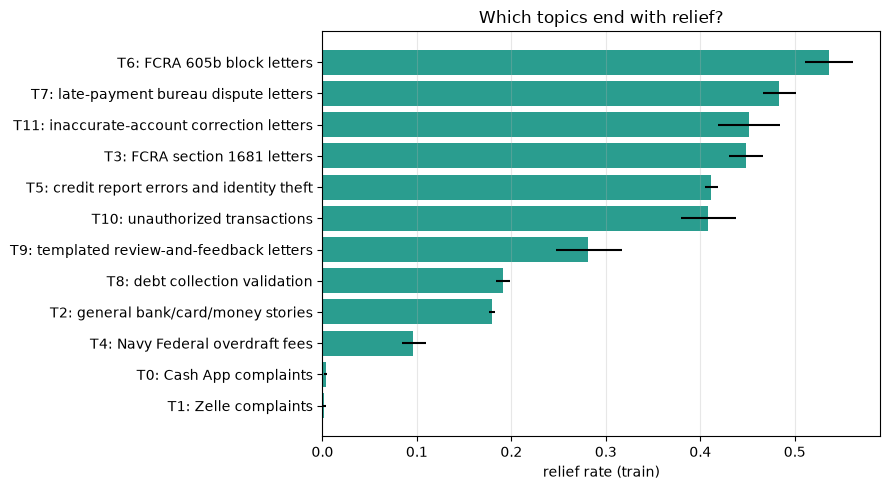

In [25]:
plot_data = topic_relief.sort_values("relief_rate")
plt.figure(figsize=(9, 5))
plt.barh(plot_data["topic"], plot_data["relief_rate"], color="#2a9d8f",
         xerr=[plot_data["relief_rate"] - plot_data["ci_low"], plot_data["ci_high"] - plot_data["relief_rate"]])
plt.xlabel("relief rate (train)")
plt.title("Which topics end with relief?")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "07_topic_relief_rate.png", dpi=140)
plt.show()

**What this does:** shows, for each product, what share of its complaints falls in each topic (each row adds up to 100%).

In [26]:
topic_by_product = pd.crosstab(df["product_group"], df["topic_label"], normalize="index")
display(topic_by_product.round(3))
topic_by_product.to_csv(REPORT_DIR / "07_topic_share_by_product.csv")

topic_label,T0: Cash App complaints,T10: unauthorized transactions,T11: inaccurate-account correction letters,T1: Zelle complaints,T2: general bank/card/money stories,T3: FCRA section 1681 letters,T4: Navy Federal overdraft fees,T5: credit report errors and identity theft,T6: FCRA 605b block letters,T7: late-payment bureau dispute letters,T8: debt collection validation,T9: templated review-and-feedback letters,none
product_group,,,,,,,,,,,,,
Bank account,0.010,0.004,0.001,0.002,0.841,0.001,0.094,0.030,0.000,0.002,0.004,0.010,0.0
Credit or prepaid card,0.001,0.006,0.004,0.000,0.731,0.009,0.007,0.105,0.002,0.109,0.025,0.001,0.0
Credit reporting,0.002,0.007,0.021,0.000,0.033,0.109,0.000,0.720,0.012,0.037,0.055,0.005,0.0
Debt collection,0.000,0.041,0.016,0.000,0.140,0.013,0.001,0.241,0.063,0.005,0.461,0.018,0.0
Debt or credit management,0.003,0.009,0.006,0.000,0.528,0.017,0.010,0.180,0.003,0.012,0.231,0.000,0.0
Money transfer / virtual currency,0.352,0.006,0.000,0.190,0.427,0.000,0.004,0.014,0.000,0.001,0.003,0.001,0.0
Mortgage,0.000,0.001,0.001,0.000,0.908,0.002,0.004,0.024,0.001,0.012,0.044,0.001,0.0
Payday / personal loan,0.002,0.001,0.004,0.000,0.779,0.011,0.010,0.099,0.000,0.011,0.083,0.001,0.0
Student loan,0.000,0.002,0.001,0.000,0.790,0.010,0.001,0.116,0.001,0.010,0.066,0.002,0.0


**What this does:** draws that table as a heat map: darker means a bigger share of the product's complaints.

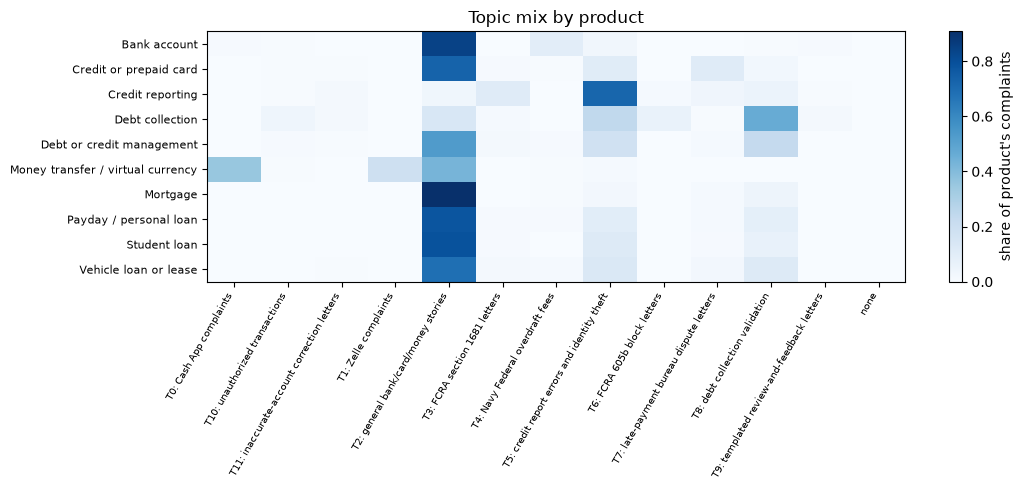

In [27]:
plt.figure(figsize=(11, 5))
plt.imshow(topic_by_product.values, aspect="auto", cmap="Blues")
plt.xticks(range(topic_by_product.shape[1]), topic_by_product.columns, rotation=60, ha="right", fontsize=7)
plt.yticks(range(topic_by_product.shape[0]), topic_by_product.index, fontsize=8)
plt.colorbar(label="share of product's complaints")
plt.title("Topic mix by product")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_topic_by_product.png", dpi=140)
plt.show()

**What this does:** compares each topic's share of complaints in train and in validation. A positive difference means the topic is **growing**,
which is exactly what a monitoring dashboard should warn about.

In [28]:
share_train = df[df["split"] == "train"]["topic_label"].value_counts(normalize=True)
share_valid = df[df["split"] == "validation"]["topic_label"].value_counts(normalize=True)
topic_shift = pd.DataFrame({"share_train": share_train, "share_validation": share_valid}).fillna(0)
topic_shift["change"] = topic_shift["share_validation"] - topic_shift["share_train"]
topic_shift = topic_shift.sort_values("change", ascending=False)
display(topic_shift)
topic_shift.to_csv(REPORT_DIR / "07_topic_share_shift.csv")

,share_train,share_validation,change
topic_label,,,
T5: credit report errors and identity theft,0.201731,0.303555,0.101824
T8: debt collection validation,0.098914,0.129633,0.030719
T10: unauthorized transactions,0.010195,0.013109,0.002914
none,0.000087,0.000162,0.000075
T9: templated review-and-feedback letters,0.006042,0.005503,-0.000539
T11: inaccurate-account correction letters,0.008306,0.005503,-0.002804
T6: FCRA 605b block letters,0.014059,0.005826,-0.008233
T7: late-payment bureau dispute letters,0.030122,0.020661,-0.009461
T2: general bank/card/money stories,0.489791,0.479204,-0.010587


**What this does:** draws the change in share, topic by topic.

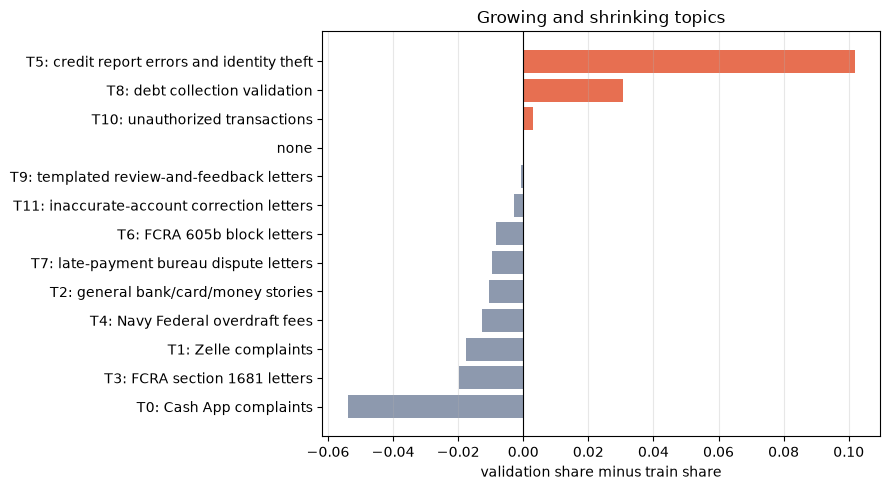

In [29]:
plot_data = topic_shift.sort_values("change")
colors = np.where(plot_data["change"] >= 0, "#e76f51", "#8d99ae")
plt.figure(figsize=(9, 5))
plt.barh(plot_data.index, plot_data["change"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("validation share minus train share")
plt.title("Growing and shrinking topics")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "07_topic_share_shift.png", dpi=140)
plt.show()

## 5. Named entities with spaCy (optional)
*Named entity recognition* (NER) finds names of organisations, money, dates and places in free text. CFPB hides many names, so expect modest results:
the point here is to see what a standard pre-trained model finds, and to show the skill.

**What this does:** runs spaCy on a random sample of 2,000 validation narratives and counts the entity types it finds. If spaCy or its small English
model is not installed, it prints how to install them and moves on.

In [30]:
try:
    import spacy
    nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])
    spacy_ready = True
except Exception as error:
    spacy_ready = False
    print("spaCy not available, skipping this section.")
    print("To enable it: pip install spacy   then   python -m spacy download en_core_web_sm")

if spacy_ready:
    sample_texts = df[df["split"] == "validation"]["narrative"].sample(2000, random_state=SEED).tolist()
    entity_labels = []
    organisation_names = []
    for doc in nlp.pipe(sample_texts, batch_size=64):
        for entity in doc.ents:
            entity_labels.append(entity.label_)
            is_only_x_mask = entity.text.strip("xX ") == ""   # CFPB hides names as XXXX; spaCy often calls those "ORG"
            if entity.label_ == "ORG" and not is_only_x_mask:
                organisation_names.append(entity.text.lower())
    label_counts = pd.Series(entity_labels).value_counts()
    print("entity types found in 2,000 narratives:")
    display(label_counts.head(10).to_frame("count"))

entity types found in 2,000 narratives:


,count
ORG,9027
PERSON,4415
GPE,2905
DATE,2420
CARDINAL,2393
MONEY,1960
LAW,459
ORDINAL,315
TIME,178
FAC,148


**What this does:** shows the 15 organisation names mentioned most often (pure `XXXX` masks are skipped). Names come from what people wrote and are
**not verified** as the company that handled the complaint.

In [31]:
if spacy_ready:
    top_organisations = pd.Series(organisation_names).value_counts().head(15)
    display(top_organisations.to_frame("mentions"))
    top_organisations.to_frame("mentions").to_csv(REPORT_DIR / "07_top_organisations_sample.csv")

,mentions
fcra,457
cfpb,344
chase,148
wells fargo,134
bank of america,122
ftc,101
the fair credit reporting act,98
capital one,91
equifax,89
paypal,74


## 6. Save the topic model
The API and dashboard steps will reuse it to tag new complaints with a topic.

**What this does:** saves the vectorizer, the NMF model and the topic labels.

In [32]:
joblib.dump({"vectorizer": topic_vectorizer, "nmf": nmf, "topic_labels": topic_labels, "stop_words": stop_words},
            MODEL_DIR / "07_topic_model.joblib", compress=3)
print("saved models/07_topic_model.joblib")
print("reports:", *sorted(p.name for p in REPORT_DIR.glob("07_*")), sep="\n  ")

saved models/07_topic_model.joblib
reports:
  07_amount_band_vs_relief.csv
  07_pii_scan.csv
  07_top_organisations_sample.csv
  07_topic_relief_rate_train.csv
  07_topic_share_by_product.csv
  07_topic_share_shift.csv
  07_topic_top_words.csv


## How to explain this in an interview
> "Besides the prediction model I analysed the text itself. A privacy scan checks for leftover personal data and builds a redaction step the API will reuse.
> I extracted dollar amounts and tested whether bigger amounts get more money back. I learned 12 topics with NMF on the training period only, named them,
> measured which topics end with relief (with confidence intervals), and tracked which topics are growing between periods. I also tried spaCy NER and
> was clear about its limits on redacted text."